# Pops’ Edge: TabPFN-v2 learner comparison

Built with PriorLabs-TabPFN.

## tl;dr

**Both new learners failed the agreed development gate.** TabPFN-v2 average annual
Brier gain over the reference was 0.000058 versus the required 0.001; its 14-day
conditional 95% interval is [−0.000225, +0.000321]. CatBoost averaged −0.000480.
The sportsbook opening proxy has better Brier/log-loss point scores in all years.
Retain the reference; no additional tuning or checkpoint automatically follows.

## Context & Methods

One approved default v2 checkpoint, four intrinsic ICL/preprocessing estimators;
existing ten features; annual expanding training; no post-fit calibration.
CatBoost has eight predeclared configurations selected using only earlier inner
season folds, then refitted without outer evaluation labels. See `PROTOCOL.md`,
`SETTINGS.json`, `checkpoint_pin.json` and `input_manifest.json`.

### Key Assumptions

2024–2026 are reused development, not untouched holdouts. Historical actual
starters are assumed identities; final corrected data and prior-day availability
remain limitations. Paired calendar-block intervals condition on fixed selected
forecasts and omit model-selection/training uncertainty. Opening consensus is
the agreed historical Kalshi proxy; no executable-return test is performed.

## Data

This notebook reads aggregate results and verification receipts only: 7,280 full
eligible games; 7,144 original market matches. Raw provider data, per-game
predictions, checkpoints and fitted contexts remain private. All annual reference
probabilities reproduced exactly. Model execution: Python 3.14.5, TabPFN 9.1.0
running explicit v2, PyTorch 2.14.1, CatBoost 1.2.10, NumPy 2.5.3, sklearn 1.9.1.
Presentation uses matplotlib, nbformat/nbclient/ipykernel independently of fits.


### 1. Load verified aggregate results

In [1]:
import json
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import display, Markdown
root=Path.cwd()
r=json.loads((root/'results.json').read_text())
v=json.loads((root/'verification.json').read_text())
mv=json.loads((root/'measurement_verification.json').read_text())
assert v['unique_games']==7280 and v['original_market_common_games']==7144
assert all(f['tabpfn_prediction_replay_max_difference']==0 for f in v['folds'])
assert not r['gates']['tabpfn_v2']['passed'] and not r['gates']['catboost']['passed']
assert mv['bootstrap_all_5000_replicates_independently_reweighted_by_game']
plt.rcParams.update({'font.size':11,'figure.dpi':140,'axes.spines.top':False,'axes.spines.right':False})
years=['2024','2025','2026']
palette={'tabpfn_v2':'#22659A','catboost':'#9B6D19','reference':'#555555'}
labels={'tabpfn_v2':'TabPFN-v2','catboost':'CatBoost','reference':'Reference','sportsbook':'Sportsbook proxy'}
print('Both continuation gates failed; exact saved-model replay passed in all years.')

Matplotlib is building the font cache; this may take a moment.


Both continuation gates failed; exact saved-model replay passed in all years.


## Results

### 2. Full-population annual Brier scores

Lower Brier is better. Each row compares identical games; market scores appear separately.

In [2]:
table='| Season | Games | Reference | CatBoost | TabPFN-v2 | V2 gain over reference |\n|---|---:|---:|---:|---:|---:|\n'
for year in years:
    a=r['annual_full'][year]
    table+=f"| {year} | {a['reference']['games']:,} | {a['reference']['brier']:.6f} | {a['catboost']['brier']:.6f} | {a['tabpfn_v2']['brier']:.6f} | {r['gates']['tabpfn_v2']['annual_brier_gains'][year]:+.6f} |\n"
display(Markdown(table))

| Season | Games | Reference | CatBoost | TabPFN-v2 | V2 gain over reference |
|---|---:|---:|---:|---:|---:|
| 2024 | 2,426 | 0.243134 | 0.244324 | 0.243272 | -0.000138 |
| 2025 | 2,426 | 0.243886 | 0.243882 | 0.243605 | +0.000280 |
| 2026 | 2,428 | 0.246136 | 0.246390 | 0.246105 | +0.000031 |


### 3. Development gains versus the gate

Positive means better than the reference. Conditional paired 14-day percentile 95% intervals; 5,000 replicates; annual average gives each season equal weight.

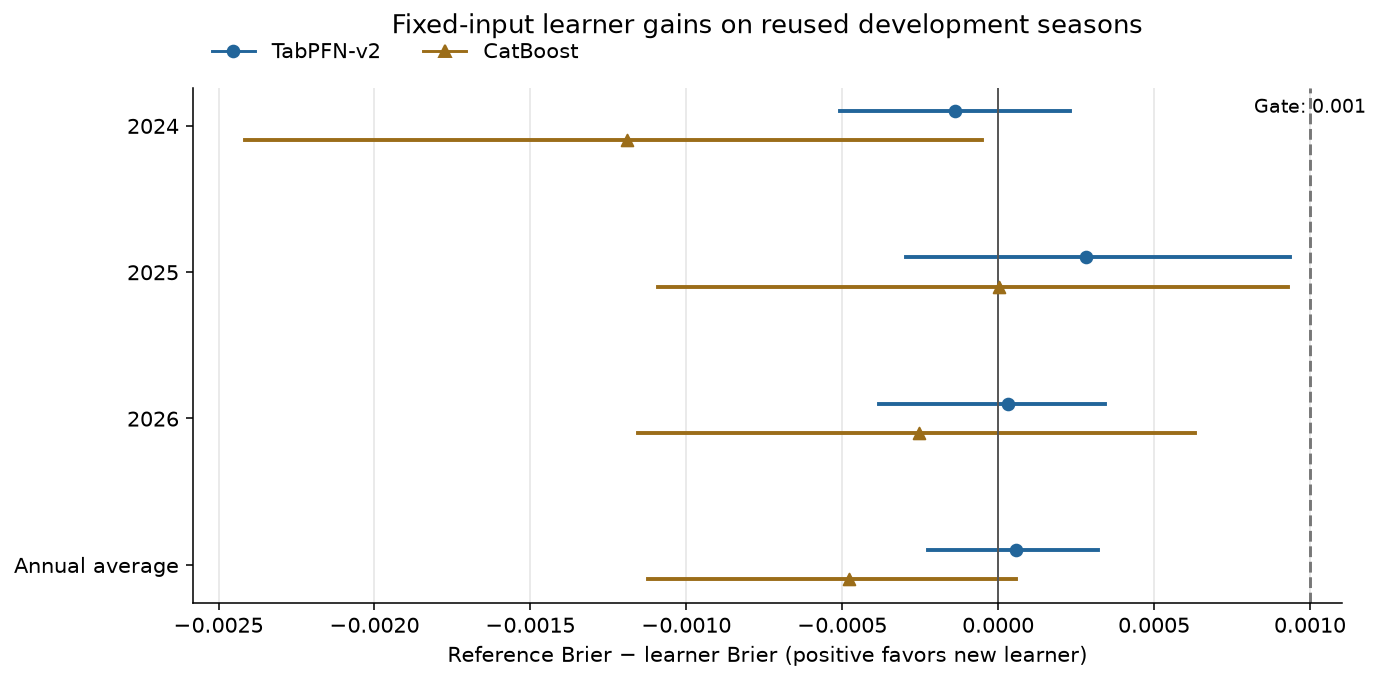

In [3]:
fig,ax=plt.subplots(figsize=(10,5))
categories=years+['Annual average']
for name,offset,marker in [('tabpfn_v2',-.10,'o'),('catboost',.10,'^')]:
    key='reference_minus_'+name
    for i,year in enumerate(categories):
        d=r['bootstrap_full']['14']['equal_weight_annual'][key]['brier'] if i==3 else r['bootstrap_full']['14']['annual'][year][key]['brier']
        ax.plot([d['lower'],d['upper']],[i+offset,i+offset],color=palette[name],linewidth=2)
        ax.scatter([d['difference']],[i+offset],color=palette[name],marker=marker,zorder=3)
ax.axvline(0,color='#555555',linewidth=1)
ax.axvline(.001,color='#777777',linestyle='--')
ax.text(.001,.98,'Gate: 0.001',transform=ax.get_xaxis_transform(),ha='center',va='top',fontsize=10)
ax.set_yticks(range(4),categories);ax.invert_yaxis()
ax.set_xlabel('Reference Brier − learner Brier (positive favors new learner)')
ax.set_title('Fixed-input learner gains on reused development seasons',pad=28)
handles=[Line2D([],[],color=palette[n],marker=m,label=labels[n]) for n,m in [('tabpfn_v2','o'),('catboost','^')]]
ax.legend(handles=handles,loc='lower left',bbox_to_anchor=(0,1.01),frameon=False,ncol=2)
ax.grid(axis='x',color='#E5E5E5');fig.tight_layout()
fig.savefig(root/'native_gains.png',dpi=180);plt.show()

TabPFN-v2 improved slightly in 2025/2026 and worsened 2024. Its average gain is far below the frozen threshold and its interval spans zero. CatBoost fails the average-gain, two-year and pooled-log-loss conditions.

### 4. Original sportsbook-proxy intersection

These pooled scores use the same 7,144 games for all four forecasts. They must not be compared directly with full-population scores above.

| Forecast | Paired games | Brier | Natural-log loss |
|---|---:|---:|---:|
| Sportsbook proxy | 7,144 | 0.242375 | 0.677902 |
| Reference | 7,144 | 0.244678 | 0.682318 |
| TabPFN-v2 | 7,144 | 0.244622 | 0.682209 |
| CatBoost | 7,144 | 0.245082 | 0.683208 |


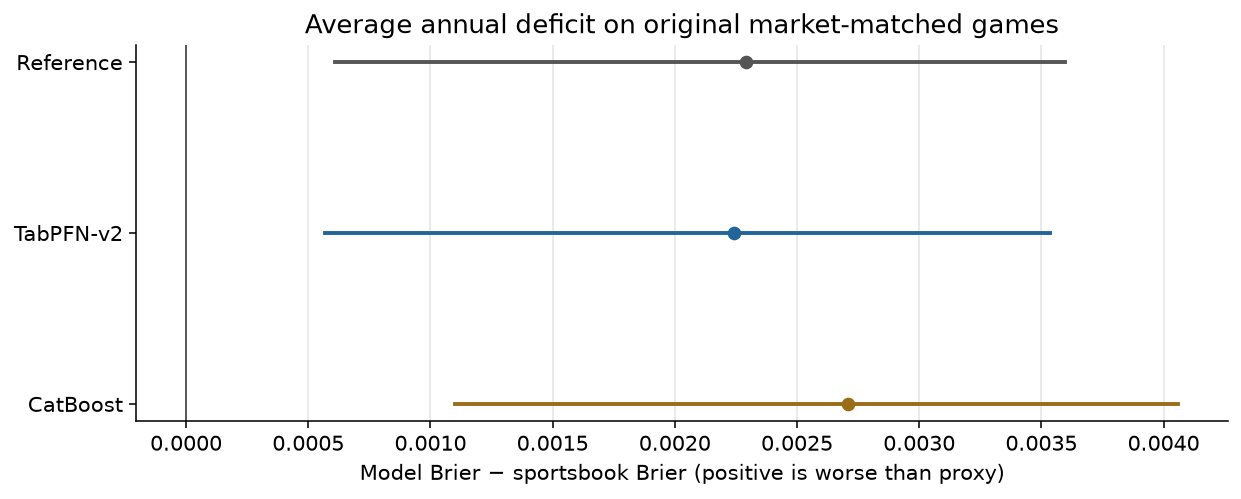

In [4]:
table='| Forecast | Paired games | Brier | Natural-log loss |\n|---|---:|---:|---:|\n'
for name in ['sportsbook','reference','tabpfn_v2','catboost']:
    a=r['pooled_market_common'][name]
    table+=f"| {labels[name]} | {a['games']:,} | {a['brier']:.6f} | {a['log_loss']:.6f} |\n"
display(Markdown(table))
fig,ax=plt.subplots(figsize=(9,3.7))
for i,name in enumerate(['reference','tabpfn_v2','catboost']):
    d=r['bootstrap_market_common']['14']['equal_weight_annual']['sportsbook_minus_'+name]['brier']
    gain=-d['difference'];lo=-d['upper'];hi=-d['lower']
    ax.plot([lo,hi],[i,i],color=palette[name],linewidth=2)
    ax.scatter([gain],[i],color=palette[name],marker='o',zorder=3)
ax.axvline(0,color='#555555',linewidth=1)
ax.set_yticks(range(3),['Reference','TabPFN-v2','CatBoost']);ax.invert_yaxis()
ax.set_xlabel('Model Brier − sportsbook Brier (positive is worse than proxy)')
ax.set_title('Average annual deficit on original market-matched games')
ax.grid(axis='x',color='#E5E5E5');fig.tight_layout()
fig.savefig(root/'sportsbook_gap.png',dpi=180);plt.show()

The proxy is better on both proper scores in all three annual comparisons. Average v2 Brier deficit is 0.002240, with conditional 14-day interval [+0.000568,+0.003533]. This does not measure executable Kalshi returns.

### 5. Calibration and readiness diagnostics

In [5]:
table='| Season | Reference slope | CatBoost slope | V2 slope |\n|---|---:|---:|---:|\n'
for year in years:
    c=r['calibration_full'][year]
    table+=f"| {year} | {c['reference']['slope']:.3f} | {c['catboost']['slope']:.3f} | {c['tabpfn_v2']['slope']:.3f} |\n"
display(Markdown(table))
print('Calibration fits are descriptive; no correction or decision threshold was fitted.')
print('No target losses removed; 136 games missing eligible sportsbook quotes remain visible.')

| Season | Reference slope | CatBoost slope | V2 slope |
|---|---:|---:|---:|
| 2024 | 0.987 | 1.337 | 0.947 |
| 2025 | 0.843 | 1.024 | 0.861 |
| 2026 | 0.782 | 0.859 | 0.800 |


Calibration fits are descriptive; no correction or decision threshold was fitted.
No target losses removed; 136 games missing eligible sportsbook quotes remain visible.


## Takeaways

Operational readiness passed: official v2 checkpoint/license verified, isolated
CPU/Metal setup, full-size synthetic capacity, network-disabled model use.
Predictive continuation failed for both v2 and the bounded boosting baseline.
Preserve results and retain the reference. No next checkpoint, calibration,
feature expansion or larger search has been launched.

This test speaks to one v2 checkpoint on our existing compressed representation.
It does not establish that a richer player/event representation cannot help.
That is a separate discussion needing concrete data and a new frozen protocol.
The 3.5 inquiry is separate and remains pending; no 3.5 access or terms accepted.

### Validation

All 7,280 saved v2 and CatBoost probabilities replay exactly from fitted artifacts.
Reference replay is exact; annual/pooled proper scores, training-only selection,
calibration score equations and every 5,000-resample bound were independently
checked by this task. Actual and synthetic later-test-row mutation checks passed.
No separate external reviewer or full raw feature-builder rerun is claimed.
See `verification.json` and `measurement_verification.json`.
